<div dir="rtl">

# مشروع صغير: تحليل طلبات مطعم بمساعدة الذكاء الاصطناعي
**السؤال الرئيسي:** أين تربح إدارة المطعم، ومتى يزدحم، وما الذي يُغضب العملاء؟

**البيانات:** `restaurant_orders.csv` (طلبات 3 فروع، يناير إلى يونيو 2025). اقرأ `data_dictionary_restaurant.md` أولًا.

**المهارات المستخدمة في Cursor:** `/data-quality-report` ← `/kpi-summary` ← `/clear-charts` ← `/insight-report`

**طريقة العمل:** لكل سؤال: اطلب من Agent الكود (أو استدعِ المهارة)، اقرأ الكود قبل قبوله، شغّله، ثم قارن بنقطة التحقق.

</div>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("restaurant_orders.csv")
print(df.shape)   # نقطة تحقق: (1515, 12)
df.head()

(1515, 12)


,order_id,order_date,order_hour,branch,channel,category,item,quantity,unit_price,total,delivery_minutes,rating
0,R10001,2025-01-01,11,Downtown,Delivery,Sides,Hummus,5,3.5,17.5,43.0,3.0
1,R10002,2025-01-01,19,Mall,Takeaway,Main,Falafel Wrap,4,4.5,18.0,NaN,4.0
2,R10003,2025-01-01,20,Downtown,Dine-in,Main,Chicken Shawarma,3,6.5,19.5,NaN,NaN
3,R10004,2025-01-01,22,University,Delivery,Main,Beef Burger,2,8.0,16.0,28.0,5.0
4,R10005,2025-01-02,11,Mall,Delivery,Drinks,Fresh Juice,3,3.0,9.0,29.0,4.0


<div dir="rtl">

## الخطوة 1: فحص الجودة والتنظيف
في Agent: `/data-quality-report افحص restaurant_orders.csv` ثم: «نظّف البيانات حسب التقرير واحفظها في clean».

**نقطة تحقق:** 15 صفًا مكررًا، و6 كتابات مختلفة لأسماء الفروع، و136 تقييمًا مفقودًا. بعد التنظيف: **1500 صف** و3 فروع فقط.

</div>

In [2]:
print("Original shape:", df.shape)
print("\nDuplicate rows:", df.duplicated().sum())
print("\nMissing values by column:")
print(df.isna().sum())
print("\nBranch spellings before cleaning:")
print(df["branch"].value_counts())

clean = df.drop_duplicates().copy()
clean["branch"] = clean["branch"].str.strip().str.title()

print("\nClean shape:", clean.shape)
print("\nBranches after cleaning:")
print(clean["branch"].value_counts())


Original shape: (1515, 12)

Duplicate rows: 15

Missing values by column:
order_id               0
order_date             0
order_hour             0
branch                 0
channel                0
category               0
item                   0
quantity               0
unit_price             0
total                  0
delivery_minutes    1137
rating               136
dtype: int64

Branch spellings before cleaning:
branch
Mall           585
Downtown       461
University     445
 university      5
DOWNTOWN         5
 mall            4
UNIVERSITY       4
MALL             3
 downtown        3
Name: count, dtype: int64

Clean shape: (1500, 12)

Branches after cleaning:
branch
Mall          590
Downtown      466
University    444
Name: count, dtype: int64


<div dir="rtl">

## الخطوة 2: مؤشرات الأداء (س1)
**س1:** ما إجمالي الإيرادات وعدد الطلبات ومتوسط قيمة الطلب ومتوسط التقييم؟ وما هي لكل فرع؟

في Agent: `/kpi-summary احسب المؤشرات العامة ثم قارن الفروع`

</div>

In [3]:
overall = pd.DataFrame({
    "Total revenue": [clean["total"].sum()],
    "Number of orders": [clean["order_id"].nunique()],
    "Average order value": [clean["total"].sum() / clean["order_id"].nunique()],
    "Average rating": [clean["rating"].mean()]
}, index=["Restaurant"])

branch_kpis = clean.groupby("branch").agg(
    **{
        "Total revenue": ("total", "sum"),
        "Number of orders": ("order_id", "nunique"),
        "Average rating": ("rating", "mean")
    }
)
branch_kpis["Average order value"] = (
    branch_kpis["Total revenue"] / branch_kpis["Number of orders"]
)
branch_kpis = branch_kpis[overall.columns]

kpi_summary = pd.concat([overall, branch_kpis])
kpi_summary.round(2)


,Total revenue,Number of orders,Average order value,Average rating
Restaurant,18751.0,1500,12.50,4.07
Downtown,6678.0,466,14.33,4.01
Mall,7933.0,590,13.45,4.12
University,4140.0,444,9.32,4.04


<div dir="rtl">

## الخطوة 3: الذروة والقنوات والأصناف (س2، س3، س4)
- **س2:** ما ساعات الذروة؟ وأي أيام الأسبوع أكثر ازدحامًا؟
- **س3:** ما حصة كل قناة (صالة، سفري، توصيل) من الإيرادات؟
- **س4:** ما أعلى 5 أصناف من حيث الإيرادات؟

ارسم رسمين على الأقل باستخدام `/clear-charts`.

</div>

Peak hour: 20 with 220 orders
Busiest weekday: Saturday with 280 orders


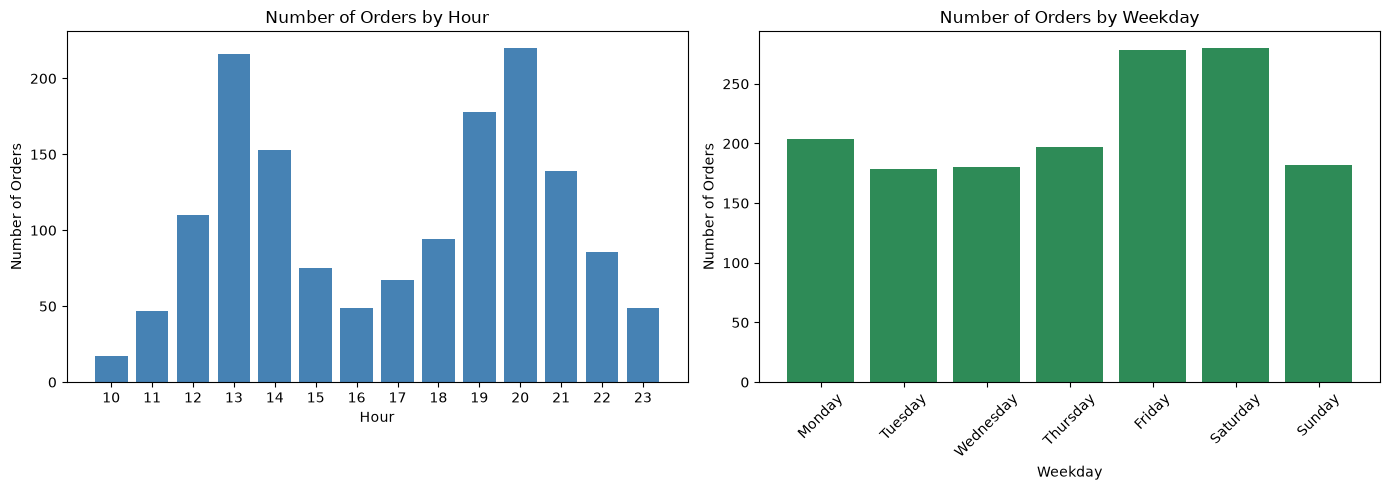

In [4]:
orders_by_hour = clean.groupby("order_hour")["order_id"].nunique().sort_index()

weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
orders_by_weekday = (
    clean.assign(weekday=pd.to_datetime(clean["order_date"]).dt.day_name())
    .groupby("weekday")["order_id"]
    .nunique()
    .reindex(weekday_order, fill_value=0)
)

print("Peak hour:", orders_by_hour.idxmax(), "with", orders_by_hour.max(), "orders")
print("Busiest weekday:", orders_by_weekday.idxmax(), "with", orders_by_weekday.max(), "orders")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(orders_by_hour.index.astype(str), orders_by_hour.values, color="steelblue")
axes[0].set_title("Number of Orders by Hour")
axes[0].set_xlabel("Hour")
axes[0].set_ylabel("Number of Orders")

axes[1].bar(orders_by_weekday.index, orders_by_weekday.values, color="seagreen")
axes[1].set_title("Number of Orders by Weekday")
axes[1].set_xlabel("Weekday")
axes[1].set_ylabel("Number of Orders")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


Revenue and share by channel:


,Revenue,Revenue share (%)
channel,,
Dine-in,8122.0,43.32
Takeaway,5459.0,29.11
Delivery,5170.0,27.57


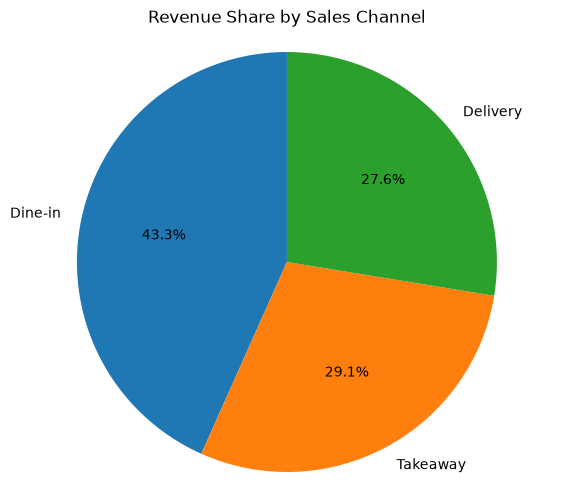

Top 5 items by revenue:


,Revenue
item,
Mixed Grill,4864.0
Grilled Chicken Plate,3399.0
Beef Burger,2464.0
Chicken Shawarma,1878.5
Falafel Wrap,1314.0


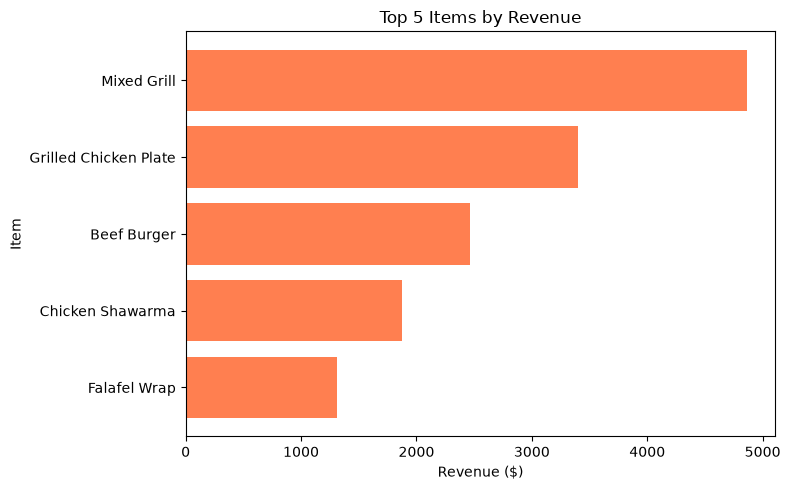

In [6]:
channel_revenue = clean.groupby("channel")["total"].sum().sort_values(ascending=False)
channel_share = channel_revenue / clean["total"].sum() * 100

channel_summary = pd.DataFrame({
    "Revenue": channel_revenue,
    "Revenue share (%)": channel_share
})
print("Revenue and share by channel:")
display(channel_summary.round(2))

plt.figure(figsize=(7, 6))
plt.pie(
    channel_revenue,
    labels=channel_revenue.index,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Revenue Share by Sales Channel")
plt.axis("equal")
plt.show()

item_revenue = clean.groupby("item")["total"].sum().sort_values(ascending=False).head(5)
print("Top 5 items by revenue:")
display(item_revenue.to_frame(name="Revenue"))

plt.figure(figsize=(8, 5))
plt.barh(item_revenue.index[::-1], item_revenue.values[::-1], color="coral")
plt.title("Top 5 Items by Revenue")
plt.xlabel("Revenue ($)")
plt.ylabel("Item")
plt.tight_layout()
plt.show()


<div dir="rtl">

## الخطوة 4: رضا العملاء (س5)
**س5:** هل يرتبط وقت التوصيل بتقييم العميل؟
قسّم طلبات التوصيل إلى ثلاث فئات: أقل من 30 دقيقة، من 30 إلى 45، أكثر من 45. ثم احسب عدد الطلبات ومتوسط التقييم لكل فئة.

> هذه مقارنة بين متوسطات، لا تحتاج أي نموذج تعلم آلي. لكنها لا تثبت السبب وحدها.

</div>

In [7]:
delivery = clean[clean["channel"] == "Delivery"].copy()

def time_group(minutes):
    if minutes < 30:
        return "Less than 30"
    elif minutes <= 45:
        return "30 to 45"
    else:
        return "More than 45"

delivery["time_group"] = delivery["delivery_minutes"].apply(time_group)

delivery_result = delivery.groupby("time_group").agg(
    Orders=("order_id", "nunique"),
    Average_Rating=("rating", "mean")
)

print(delivery_result.round(2))

              Orders  Average_Rating
time_group                          
30 to 45         200            3.59
Less than 30      69            4.11
More than 45     105            2.47


<div dir="rtl">

## الخطوة 5: الرؤى والتوصيات (س6)
في Agent: `/insight-report اكتب الرؤى والتوصيات من نتائج هذا الدفتر واحفظها في insights.md`

ثم راجع: هل كل رقم في التقرير موجود فعلًا في مخرجات الدفتر؟ سجّل أي خطأ في سجل التحقق أدناه.

## سجل التحقق
| ماذا قال الذكاء الاصطناعي | كيف تحققت | النتيجة |
| --- | --- | --- |
| إجمالي المطعم: 18,751 دولارًا، 1,500 طلب، متوسط الطلب 12.50 دولارًا، والتقييم 4.07 | مقارنة أرقام التقرير بجدول مؤشرات الأداء في مخرجات س1 | مطابقة |
| الفروع: Downtown ‏6,678 دولارًا و466 طلبًا ومتوسط 14.33 وتقييم 4.01؛ Mall ‏7,933 و590 ومتوسط 13.45 وتقييم 4.12؛ University ‏4,140 و444 ومتوسط 9.32 وتقييم 4.04 | مقارنة صفوف الفروع في جدول س1 | مطابقة |
| الذروة 20:00 (220 طلبًا)، والسبت (280 طلبًا) | مقارنة بمخرجات س2 | مطابقة |
| القنوات: الصالة 8,122 دولارًا (43.32%)، السفري 5,459 (29.11%)، التوصيل 5,170 (27.57%) | مقارنة بجدول القنوات في مخرجات س3، والمجموع 18,751 دولارًا | مطابقة |
| أعلى الأصناف: Mixed Grill ‏4,864 دولارًا؛ Grilled Chicken Plate ‏3,399؛ Beef Burger ‏2,464؛ Chicken Shawarma ‏1,878.50؛ Falafel Wrap ‏1,314 | مقارنة بجدول أعلى خمسة أصناف في مخرجات س4 | مطابقة |
| أقل من 30 دقيقة: 69 طلبًا وتقييم 4.11؛ 30–45: 200 و3.59؛ أكثر من 45: 105 و2.47 | مقارنة بجدول س5؛ مجموع الطلبات 374 | مطابقة |

</div>